<a href="https://colab.research.google.com/github/enoch26/2026-ml-esm-training/blob/main/1_3_Additional_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1.3 Additional Exercises

In this notebook, we explore different coding examples and exercises to become more familiar with PyTorch. Feel free to choose those that you find most interesting.

- **A**: [Gradients](#A)
- **B**: [More on tensor operations](#B)
- **C**: [Custom parameters](#C)
- **D**: [Linear regression](#D)
- **E**: [Multi-layer perceptron regression](#E)
- **F**: [Save and load models](#F)
- **G**: [Logistic regression](#G)
- **H**: [Custom loss function](#H)

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

<a name="A"></a>
## A) Gradients

Autograd, short for automatic differentiation, is a fundamental concept in PyTorch that enables automatic computation of gradients for tensor operations. It is a key component of PyTorch's dynamic computational graph, allowing users to easily compute gradients with respect to input tensors.

**Exercise 1**: Explain the code below. What does each line of code do?

In [2]:
# Create a tensor with requires_grad=True
x = torch.tensor([2.0], requires_grad=True)

# Perform a mathematical operation
y = x**2 + 3*x + 1

# Compute the gradient
y.backward()

# Access the gradient
gradient = x.grad

print("Original Tensor (x):", x.item())
print("Result of the Operation (y):", y.item())
print("Gradient with respect to x:", gradient.item())

Original Tensor (x): 2.0
Result of the Operation (y): 11.0
Gradient with respect to x: 7.0


**Exercise 2**: Compute the gradient of $y = x^2 + 3\cdot x + 1$ for a whole range of values of x (from -5 to 5) and plot your results.

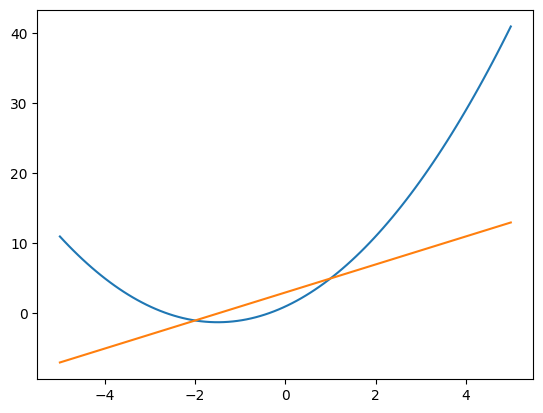

In [12]:
import torch
import matplotlib.pyplot as plt

# Create a tensor with requires_grad=True
x_values = torch.linspace(-5, 5, 100, requires_grad=True)

# Compute y, compute gradients and plot both y and dy/dx as a function of x.


#[INSERT YOUR CODE HERE]

y = x_values**2 + 3*x_values + 1
y.sum().backward()
gradient = x_values.grad

# print("Original Tensor (x):", x_values.detach().numpy())
# print("Result of the Operation (y):", y.detach().numpy())
# print("Gradient with respect to x:", gradient.detach().numpy())

plt.plot(x_values.detach().numpy(), y.detach().numpy(), label='y')
plt.plot(x_values.detach().numpy(), gradient.detach().numpy(), label='dy/dx')


<a name="B"></a>
## B) More on tensor operations

**Exercise 3**: Have a look at more examples on PyTorch's tensors on their own [homepage](https://pytorch.org/tutorials/beginner/introyt/tensors_deeper_tutorial.html).

**Exercise 4**: The code below is missing comments. Explain the code.

In [13]:
import torch

tensor_2d = torch.tensor([[1, 2, 3],
                          [4, 5, 6],
                          [7, 8, 9]])

print("Original 2D Tensor:")
print(tensor_2d)
print()

element_00 = tensor_2d[0, 0]
element_12 = tensor_2d[1, 2]

print("Individual Elements:")
print("Element at [0, 0]:", element_00.item())
print("Element at [1, 2]:", element_12.item())
print()

submatrix_row1 = tensor_2d[1, :]
submatrix_col2 = tensor_2d[:, 2]

print("Submatrices:")
print("Second Row:", submatrix_row1)
print("Third Column:", submatrix_col2)

Original 2D Tensor:
tensor([[1, 2, 3],
        [4, 5, 6],
        [7, 8, 9]])

Individual Elements:
Element at [0, 0]: 1
Element at [1, 2]: 6

Submatrices:
Second Row: tensor([4, 5, 6])
Third Column: tensor([3, 6, 9])


**Exercise 5**: Concatenate two 1D tensors along a specified dimension. Print the original tensors and the result after concatenation.



In [30]:
tensor_1d = torch.flatten(tensor_2d)
print(tensor_1d)
tensor_1d_ = torch.cat([tensor_1d, tensor_1d])
print(tensor_1d_)


tensor([1, 2, 3, 4, 5, 6, 7, 8, 9])
tensor([1, 2, 3, 4, 5, 6, 7, 8, 9, 1, 2, 3, 4, 5, 6, 7, 8, 9])




**Exercise 6**: Create two tensors of the same shape and perform element-wise comparisons (e.g., greater than, equal to). Print the original tensors and the results of each comparison.

In [32]:
tensor_2d_ = tensor_2d + 1
print(tensor_2d_)
print(tensor_2d_ > tensor_2d)

tensor([[ 2,  3,  4],
        [ 5,  6,  7],
        [ 8,  9, 10]])
tensor([[True, True, True],
        [True, True, True],
        [True, True, True]])


<a name="C"></a>
## C) Custom Parameters

As we saw in 1.1, `nn.Module` has two important methods:

1. **`__init__`** constructs and stores the layers.
2. **`forward`** describes how an input tensor moves through those layers.

During initialisation, PyTorch *registers* the module parameters. For the `SimpleNet` case, the parameters were registered 'under the hood' by the linear layers.

We can explicitly register parameters using PyTorch's `nn.Parameter()`:

**Exercise 7**: Fill in the missing line in the class below:

In [33]:
class LinearModel(nn.Module):
    def __init__(self):
        # [TODO] something is missing here
        super().__init__()
        # w is registered as a parameter
        self.w = nn.Parameter(torch.tensor(1.))

    def forward(self, x):
        return self.w @ x

In [34]:
model = LinearModel()

# We can see the that the parameter has been registered and 'requires_grad'
model.w

Parameter containing:
tensor(1., requires_grad=True)

**Exercise 8**: Add in a scalar bias parameter called $b$, initialised at zero and edit the forward function to compute $\hat{y} = w \cdot x + b$. Print `model.state_dict()` to see what is stored here.

In [35]:
class LinearModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.w = nn.Parameter(torch.tensor(1.))
        self.b = nn.Parameter(torch.tensor(0.))

    def forward(self, x):
        return self.w * x + self.b

In [36]:
model = LinearModel()
model.state_dict()
print(model.state_dict())

OrderedDict({'w': tensor(1.), 'b': tensor(0.)})


<a name="D"></a>
## D) Linear Regression

PyTorch can facilitate many other analyses and be used to create models outside of Deep Learning. For instance, one can use PyTorch for linear regression. Actually, all you have to do is to change the model. Indeed, linear regression can be achieved using a neural network with a single layer. Beyond this change, the logic of the rest of the code stays the same. We assume Gaussian noise and hence try to minimise the mean squared errors rather than the cross entropy.

Note the class you wrote in **B)** is essentially the same as below:


In [37]:
class LinearRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(1,1)
    def forward(self, x):
        return self.linear(x)


Suppose we observe scalar inputs $x$ and noisy outputs $y$. We generate data here as an example:

$$
y = 2x + 1 + 0.4\sin(6\pi x) + \epsilon,
\qquad \epsilon \sim \mathcal{N}(0, 0.05^2).
$$

In [38]:
n_samples = 100

# shape [100, 1], i.e. a batch of 100 inputs, of 1 dimension
x = torch.rand(n_samples,1)
noise = 0.05 * torch.randn(n_samples,1)

y = 2 * x + 1 + 0.4 * torch.sin(6 * torch.pi * x) + noise

print("x shape:", x.shape)
print("y shape:", y.shape)

x shape: torch.Size([100, 1])
y shape: torch.Size([100, 1])


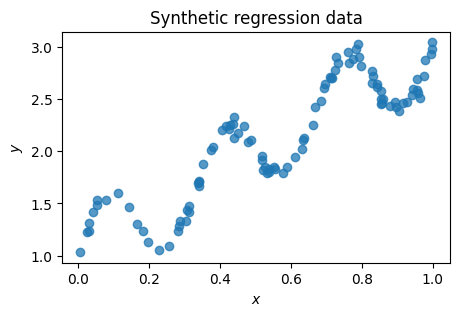

In [39]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.scatter(x, y, alpha=0.75)
ax.set(xlabel="$x$", ylabel="$y$", title="Synthetic regression data")
plt.show()

Now we can train this model as we have done with the neural nets before - here the paramters are just the weight w and bias b. Solving the ordinary least-squares problem corresponds to minimising the mean squared error (MSE). This compares targets $y_i$ with predictions $\hat y_i$:

$$
J(\theta)=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2,
$$

where $\theta$ denotes all parameters of the model. We can use torch's `nn.MSELoss()` as our loss function here.

**Exercise 9**: complete the function for running the training loop below, filling out each of the missing steps:  

In [44]:
def train_model(model, x, y, loss_fn, optimiser, n_epochs, print_every=50):
    """Train a model on one full batch and return the loss history."""
    model.train()
    history = []

    for epoch in range(n_epochs):
        # 1. Zero the gradients
        # [TODO]
        optimiser.zero_grad()
        # 2. Forward pass
        y_hat = model(x)

        # 3. Compute the loss
        # [TODO]
        loss = loss_fn(y_hat, y)
        # 4. Compute gradients
        # [TODO]
        loss.backward()
        # 5. Update paramemeters
        # [TODO]
        optimiser.step()
        history.append(loss.item())

        if epoch % print_every == 0 or epoch == n_epochs - 1:
            print(f"epoch {epoch:4d} | loss {loss.item():.5f}")

    return history

In [41]:
def train_model(model, x, y, loss_fn, optimiser, n_epochs, print_every=50):
    """Train a model on one full batch and return the loss history."""
    model.train()
    history = []

    for epoch in range(n_epochs):
        optimiser.zero_grad()
        predictions = model(x)
        loss = loss_fn(predictions, y)
        loss.backward()
        optimiser.step()

        history.append(loss.item())

        if epoch % print_every == 0 or epoch == n_epochs - 1:
            print(f"epoch {epoch:4d} | loss {loss.item():.5f}")

    return history

In [42]:
linear_model = LinearRegression()
loss_fn = nn.MSELoss()
optimiser = torch.optim.SGD(linear_model.parameters(), lr=0.1)

linear_history = train_model(linear_model, x, y, loss_fn, optimiser, n_epochs=200, print_every=50)

epoch    0 | loss 3.21929
epoch   50 | loss 0.08342
epoch  100 | loss 0.07390
epoch  150 | loss 0.07104
epoch  199 | loss 0.07019


The plot below shows the loss history and the final fit.

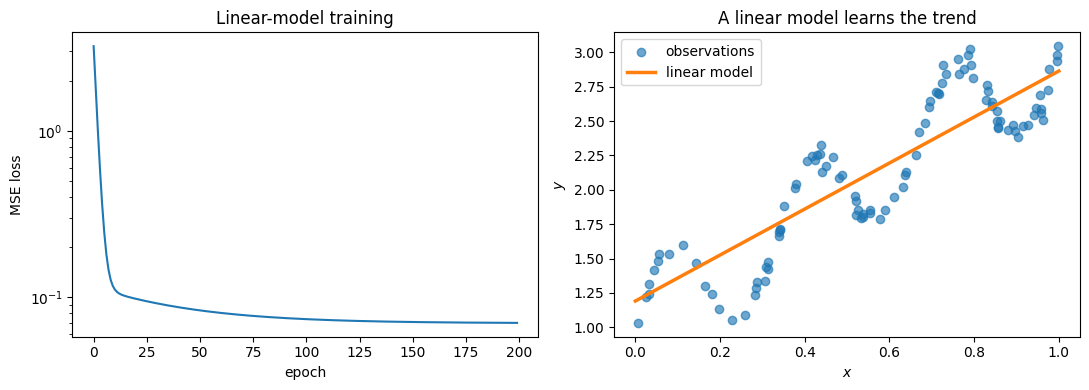

In [43]:
linear_model.eval()
x_plot = torch.linspace(0, 1, 200).reshape(-1, 1)

with torch.no_grad():
    linear_fit = linear_model(x_plot)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(linear_history)
ax[0].set(xlabel="epoch", ylabel="MSE loss", title="Linear-model training")
ax[0].set_yscale("log")

ax[1].scatter(x, y, alpha=0.65, label="observations")
ax[1].plot(x_plot, linear_fit, color="tab:orange", linewidth=2.5, label="linear model")
ax[1].set(xlabel="$x$", ylabel="$y$", title="A linear model learns the trend")
ax[1].legend()

plt.tight_layout()
plt.show()

<a name="E"></a>
## E) Multi-Layer Perceptron Regression

> **NOTE:** Complete D) before attempting this set of exercises

We can do better than a linear regression. Why not try and approximate this function with a neural network?


In [45]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(1, 32)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x


$$
\text{Linear Regression: }
\hat{y} = w \cdot x + b,
\quad
\text{Neural Network: }
\hat{y} = W_2  \cdot \sigma(W_1 \cdot x + b_1) + b_2
$$

The linear regression paramters were the scalar weight and bias $\{w, b\}$. The neural network (defined in the next cell) contains two sets of weight and bias vectors $\{W_1, b_1, W_2, b_2\}$ which we can train to minimise the MSE.


In [46]:
neural_model = MLP()
neural_model.state_dict().keys()

odict_keys(['fc1.weight', 'fc1.bias', 'fc2.weight', 'fc2.bias'])

**Exercise 10**: Below is a simple multi-layer perceptron, which we train using the same `train_model` function before. Initially the performance is only slightly better than the linear regression. Try and improve the fit by adjusting:
- hidden dimension
- activation function
- learning rate
- number of epochs
- number of layers

In [47]:
neural_optimiser = torch.optim.Adam(neural_model.parameters(), lr=0.01)

N_EPOCHS = 1000
neural_history = train_model(
    model=neural_model,
    x=x,
    y=y,
    loss_fn=loss_fn,
    optimiser=neural_optimiser,
    n_epochs=N_EPOCHS,
    print_every=N_EPOCHS//5,
)

epoch    0 | loss 5.35693
epoch  200 | loss 0.06783
epoch  400 | loss 0.06658
epoch  600 | loss 0.06440
epoch  800 | loss 0.06050
epoch  999 | loss 0.05566


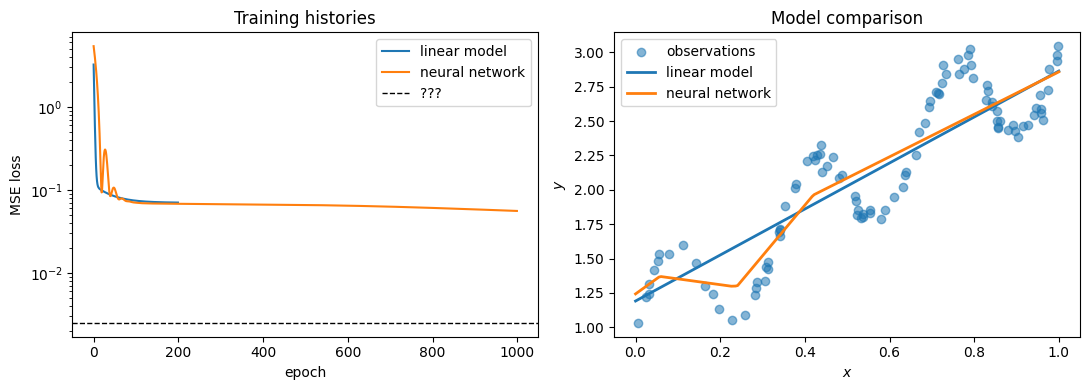

linear-model MSE:  0.07018
neural-network MSE: 0.05563


In [48]:
neural_model.eval()

with torch.no_grad():
    neural_fit = neural_model(x_plot)
    final_linear_loss = loss_fn(linear_model(x), y).item()
    final_neural_loss = loss_fn(neural_model(x), y).item()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(linear_history, label="linear model")
ax[0].plot(neural_history, label="neural network")
ax[0].set(xlabel="epoch", ylabel="MSE loss", title="Training histories")
ax[0].set_yscale("log")
ax[0].axhline(0.05**2, color='k', lw=1, ls='--', label='???')
ax[0].legend()


ax[1].scatter(x, y, alpha=0.55, label="observations")
ax[1].plot(x_plot, linear_fit, linewidth=2, label="linear model")
ax[1].plot(x_plot, neural_fit, linewidth=2, label="neural network")
ax[1].set(xlabel="$x$", ylabel="$y$", title="Model comparison")
ax[1].legend()


plt.tight_layout()
plt.show()

print(f"linear-model MSE:  {final_linear_loss:.5f}")
print(f"neural-network MSE: {final_neural_loss:.5f}")

**Exercise 11**: explain why there is a
dashed black line in MSE plot on the left. What would it mean for our neural network loss to drop below this line?

<a name="F"></a>
## F) Save and load models

**Exercise 12**: Once you have created a model (be it a linear model or a deep neural network), you can save it to file. Later you can load it again. How do you do that in PyTorch?

In [ ]:
# Save model parameters
torch.save(model.state_dict(), "model.pth")

<a name="G"></a>
## G) Logistic regression

As illustrated above with the linear fit to data, you can train other models, using PyTorch

In [49]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Generate synthetic data
torch.manual_seed(42)
X_positive = torch.randn(100, 2) + torch.tensor([2, 2])
X_negative = torch.randn(100, 2) + torch.tensor([-2, -2])
X = torch.cat([X_positive, X_negative], dim=0)
y = torch.cat([torch.ones(100), torch.zeros(100)])

# Shuffle the data
shuffle_indices = torch.randperm(len(X))
X = X[shuffle_indices]
y = y[shuffle_indices]

# Define a simple logistic regression model
class LogisticRegression(nn.Module):
    def __init__(self):
        super(LogisticRegression, self).__init__()
        self.linear = nn.Linear(2, 1)

    def forward(self, x):
        return torch.sigmoid(self.linear(x))

# Instantiate the model, loss function, and optimizer
model = LogisticRegression()
criterion = nn.BCELoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

**Exercise 13**: In logistic regression, we address a binary classification task. What is logistic regression? Explain the code above and plot the data to get an overview of the synthetic data set. Then train the model.


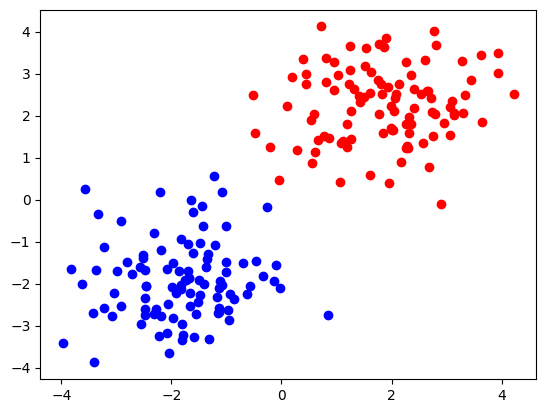

In [50]:
plt.scatter(X_positive[:, 0], X_positive[:, 1], label='Positive', color='red')
plt.scatter(X_negative[:, 0], X_negative[:, 1], label='Negative', color='blue')

In [54]:
# 1. Instantiate the specific model we want to train
logistic_model = LogisticRegression()

# 2. Re-create the optimizer for this specific model instance
logistic_optimizer = optim.SGD(logistic_model.parameters(), lr=0.1)

# 3. Reshape y from [200] to [200, 1] to match the model's output dimension
y_reshaped = y.unsqueeze(1).float()

# 4. Train the model using the matching model and optimizer
N_EPOCHS = 1000
Logistic_history = train_model(
    model=logistic_model,
    x=X,
    y=y_reshaped,
    loss_fn=criterion,
    optimiser=logistic_optimizer,
    n_epochs=N_EPOCHS,
    print_every=N_EPOCHS//5,
)

epoch    0 | loss 2.11952
epoch  200 | loss 0.02303
epoch  400 | loss 0.01547
epoch  600 | loss 0.01241
epoch  800 | loss 0.01066
epoch  999 | loss 0.00950


**Exercise 14**: Modify the synthetic data generation to introduce class imbalance (e.g., 80% negative samples and 20% positive samples). Retrain the logistic regression model and observe its performance. How do you deal with imbalanced data?

--- Training on Imbalanced Data ---
epoch    0 | loss 1.10483
epoch  200 | loss 0.04016
epoch  400 | loss 0.02809
epoch  600 | loss 0.02309
epoch  800 | loss 0.02020
epoch  999 | loss 0.01825


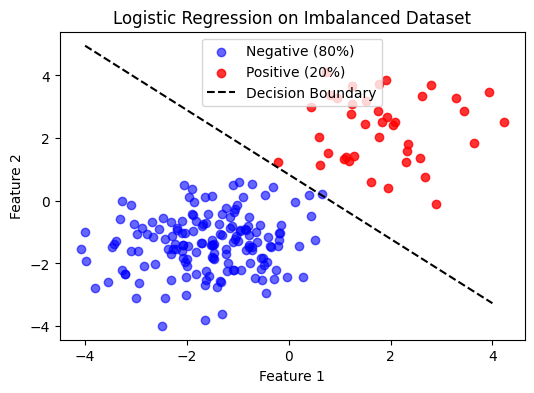

In [56]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# 1. Generate imbalanced synthetic data (80% negative, 20% positive)
torch.manual_seed(42)
n_total = 200
n_pos = int(n_total * 0.2)  # 40 samples
n_neg = int(n_total * 0.8)  # 160 samples

X_positive = torch.randn(n_pos, 2) + torch.tensor([2, 2])
X_negative = torch.randn(n_neg, 2) + torch.tensor([-1.5, -1.5])

X_imbalanced = torch.cat([X_positive, X_negative], dim=0)
y_imbalanced = torch.cat([torch.ones(n_pos), torch.zeros(n_neg)])

# Shuffle the imbalanced data
shuffle_indices = torch.randperm(len(X_imbalanced))
X_imbalanced = X_imbalanced[shuffle_indices]
y_imbalanced = y_imbalanced[shuffle_indices].unsqueeze(1).float()

# 2. Instantiate new model and optimizer
imbalanced_model = LogisticRegression()
imbalanced_optimizer = optim.SGD(imbalanced_model.parameters(), lr=0.1)
criterion = nn.BCELoss()

# 3. Retrain the model
print("--- Training on Imbalanced Data ---")
imbalanced_history = train_model(
    model=imbalanced_model,
    x=X_imbalanced,
    y=y_imbalanced,
    loss_fn=criterion,
    optimiser=imbalanced_optimizer,
    n_epochs=1000,
    print_every=200
)

# 4. Plot the data and decision boundary
plt.figure(figsize=(6, 4))
plt.scatter(X_negative[:, 0], X_negative[:, 1], label='Negative (80%)', color='blue', alpha=0.6)
plt.scatter(X_positive[:, 0], X_positive[:, 1], label='Positive (20%)', color='red', alpha=0.8)

# Plot decision boundary (where sigmoid output is 0.5, i.e., w1*x1 + w2*x2 + b = 0)
with torch.no_grad():
    w = imbalanced_model.linear.weight[0]
    b = imbalanced_model.linear.bias[0]
    x_boundary = torch.linspace(-4, 4, 100)
    y_boundary = -(w[0] * x_boundary + b) / w[1]
    plt.plot(x_boundary, y_boundary, color='black', linestyle='--', label='Decision Boundary')

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Logistic Regression on Imbalanced Dataset')
plt.legend()
plt.show()

<a name="H"></a>
## H) Custom loss function

Rather than using an existing loss function, you can create your own.

In [57]:
import torch
import torch.nn as nn

# Custom Loss Function
class CustomLoss(nn.Module):
    def __init__(self):
        super(CustomLoss, self).__init__()

    def forward(self, predictions, targets):
        # Custom loss computation
        loss = torch.mean((predictions - targets)**2)
        return loss

**Exercise 15**: The loss function above is just the MSE. Use the custom loss function for linear regression.

--- Training with Custom Loss Function ---
epoch    0 | loss 22.21524
epoch  100 | loss 0.54221
epoch  200 | loss 0.20078
epoch  300 | loss 0.19519
epoch  400 | loss 0.19509
epoch  499 | loss 0.19509


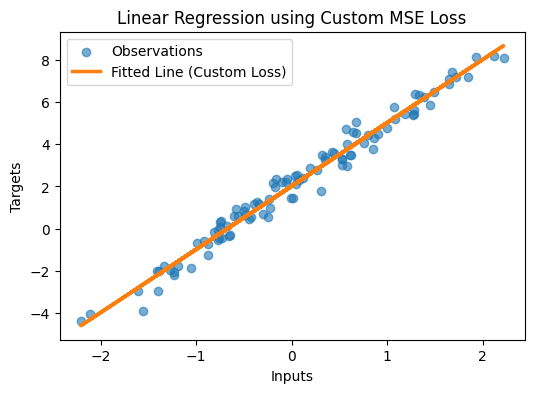

In [58]:
import torch.optim as optim
import matplotlib.pyplot as plt

# Linear Regression Model
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super(LinearRegressionModel, self).__init__()
        self.linear = nn.Linear(1, 1)

    def forward(self, x):
        return self.linear(x)

# Instantiate the model, custom loss, and optimizer
model = LinearRegressionModel()
loss_fn = CustomLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

# Generate synthetic data
torch.manual_seed(42)
inputs = torch.randn(100, 1)
targets = 3 * inputs + 2 + 0.5 * torch.randn(100, 1)

# Training loop and plot results
#[INSERT CODE HERE]

**Exercise 16**: Explore the homepage of PyTorch and the Kaggle. Find at least three useful examples and references on Deep Neural Networks (with fully connected layers) and computer vision that you have not been pointed to in these notebooks and discuss them in the group.

**Exercise 17**: Discuss the content of today's lecture and the notebooks. What are the main concepts to take home? Are there any aspects (of the content or Python programming) that you feel you need to dive further into before watching the next lecture? Discuss in the group.

**Exercise 18**: Can you, so far, see any applications of the concepts presented in this course to your research?

**Exercise 19**: In the event that your group has finished all exercises in notebooks 1.1, 1.2, and 1.3 within the first tutorial and you still have time left, please go to exercises 14 and 15 in notebook 3.2.